# Ujian Tengah Semester Graf Sains Data
**Elvira Tiara Suci Tambunan - 24031554213**
- **P1 = 20 Juni - 28 Juni 2015**
- **P2 = 28 Juni - 6 Juli 2015**

In [52]:
%pip install -r requirements.txt

  Using cached jupyter-1.1.1-py2.py3-none-any.whl.metadata (2.0 kB)
  Using cached jupyter_console-6.6.3-py3-none-any.whl.metadata (5.8 kB)
Using cached jupyter-1.1.1-py2.py3-none-any.whl (2.7 kB)
Using cached jupyter_console-6.6.3-py3-none-any.whl (24 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Tugas Pendahuluan

### 1.1 Persiapan dan Perkenalan Lingkungan

Lingkungan kerja dibuat terpisah (terisolasi) dengan `venv`, mengikuti instruksi soal:

```
python -m venv myenv
myenv\Scripts\Activate.ps1
```

Perintah aktivasi `myenv\Scripts\Activate.ps1` adalah padanan di Windows untuk `source myenv/bin/activate`. Langkah `conda deactivate` tidak diperlukan karena tidak ada environment conda yang aktif. Versi Python yang digunakan adalah 3.12.

`requirements.txt` pada soal tidak dipasang apa adanya, dengan dua alasan:

- `neo4j==4.2.1` diganti dengan **neo4j 6.4.1**, karena method `driver.execute_query()` yang dipakai pada tutorial 1.2 baru tersedia mulai driver versi 5. Versi 6.4 juga sesuai dengan yang dirujuk pada soal bagian 1.3 ("Neo4J Driver 6.4").
- Paket `imdbpy`, `nose`, `cinemagoerng`, dan `imdbinfo` tidak dipasang karena tidak digunakan pada soal ini (paket tersebut untuk mengambil data film IMDb).

Paket yang dipasang antara lain neo4j, pandas, numpy, scipy, scikit-learn, networkx, matplotlib, tqdm, dan jupyter. Daftar lengkap beserta versinya disimpan pada `requirements.txt` (hasil `pip freeze` dari environment ini), dan sel di bawah memasangnya.

### 1.2 Mempelajari Penggunaan Driver Neo4J

In [71]:
from getpass import getpass
from neo4j import GraphDatabase, RoutingControl

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", getpass("Password Neo4j: "))

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.verify_connectivity()
    print("Terhubung ke Neo4j!")
    records, _, _ = driver.execute_query(
        "SHOW DATABASES YIELD name, currentStatus RETURN name, currentStatus",
        database_="system",
    )
    for r in records:
        print(r["name"], "-", r["currentStatus"])

Terhubung ke Neo4j!
neo4j - online
system - online


In [ ]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j",
    )

def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


### Pertanyaan Pendahuluan (Checkpoint)

**1. Apa nama database yang digunakan pada tutorial ini?**
Nama database yang digunakan adalah **`neo4j`**, yaitu database default pada instance Neo4j. Hal ini terlihat dari parameter `database_="neo4j"` pada `execute_query`. Hasil `SHOW DATABASES` juga menampilkan dua database, yaitu `neo4j` (database pengguna) dan `system` (database internal untuk administrasi).

**2. Sebutkan akses lain (sintaks DDL/DML CYPHER) yang dapat digunakan untuk mengakses database lain dalam 1 instance!**
- **Klausa `USE` (DML):** `USE namadb MATCH (n) RETURN count(n)` menjalankan query pada database `namadb`. Di Neo4j Browser dapat memakai perintah `:use namadb`.
- **Parameter driver Python:** `driver.execute_query(..., database_="namadb")` atau `driver.session(database="namadb")`.
- **DDL pada database `system`:** `SHOW DATABASES` (melihat daftar database), `CREATE DATABASE namadb` (membuat), `START DATABASE namadb` / `STOP DATABASE namadb` (menyalakan/mematikan), dan `DROP DATABASE namadb` (menghapus). Perintah ini dijalankan dengan `database_="system"`.
- Perlu dicatat, fitur lebih dari satu database pengguna hanya tersedia pada edisi yang mendukung multi-database (Enterprise/Neo4j Desktop).

**3. Apa jenis graf pertemanan yang telah dibuat di sini?**
Graf yang dibuat adalah **graf berarah (directed graph)**, karena relasi `KNOWS` bergerak satu arah dari Arthur ke Guinevere, Lancelot, dan Merlin. Graf ini juga **tidak berbobot** (relasi tidak memiliki nilai bobot), berbentuk **graf bintang (star)** dengan Arthur sebagai simpul pusat yang terhubung ke 3 simpul lain, serta tidak memiliki siklus. Secara model data, graf ini adalah *property graph*: simpul berlabel `Person` dengan properti `name`, dan relasi bertipe `KNOWS`.

In [ ]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.execute_query("MATCH (n) DETACH DELETE n", database_="neo4j")
    records, _, _ = driver.execute_query("MATCH (n) RETURN count(n) AS jumlah", database_="neo4j")
    print("Jumlah simpul sekarang:", records[0]["jumlah"])

Jumlah simpul sekarang: 0


### 1.3 Dataset RetailRocket

**Poin 1: Unduh data.** Dataset *E-commerce dataset* (RetailRocket, sumber data: Roman Zykov) diunduh dari Kaggle memakai Windows PowerShell:

```
curl.exe -L -o ecommerce-dataset.zip https://www.kaggle.com/api/v1/datasets/download/retailrocket/ecommerce-dataset
```

Berkas zip (sekitar 290 MB) diekstrak ke folder `data/`. Isinya `events.csv`, `category_tree.csv`, `item_properties_part1.csv`, dan `item_properties_part2.csv`. Pada soal ini hanya `events.csv` yang digunakan, karena yang dianalisis adalah interaksi pengunjung dengan produk.

**Poin 2: Fitur pada `events.csv`.** Berkas ini berisi 2.756.101 baris dan 5 kolom, mencatat interaksi pengunjung pada 3 Mei 2015 sampai 18 September 2015.

| Kolom | Penjelasan | Peran pada graf Neo4j |
|---|---|---|
| `timestamp` | Waktu kejadian dalam format UNIX epoch (milidetik, UTC) | Dasar filter periode P1 dan P2; disimpan sebagai properti `timestamp` pada relasi |
| `visitorid` | ID unik pengunjung | Simpul `Visitor` (properti `visitorId`), diasumsikan sebagai *User* |
| `event` | Jenis interaksi: `view`, `addtocart`, `transaction` | Menentukan jenis relasi: `VIEWED`, `ADDED_TO_CART`, `BOUGHT` |
| `itemid` | ID unik produk | Simpul `Item` (properti `itemId`) |
| `transactionid` | ID transaksi, hanya terisi saat `event` bernilai `transaction` (selain itu kosong/NaN) | Properti `transactionId` pada relasi `BOUGHT`; nilai kosong diubah menjadi string kosong saat impor |

Data yang diimpor ke Neo4j bukan `events.csv` utuh, melainkan hasil filter periode P1 (`events_p1.csv`), seperti dijelaskan pada bagian 2.1.

## 2.1 Wrangling dan EDA

### 2.1.1 Penentuan Periode Data

Data interaksi dibagi menjadi dua periode berurutan: P1 digunakan untuk training dan P2 untuk testing. Masing-masing berlangsung 8 hari. P2 dimulai tepat saat P1 berakhir, tanpa hari jeda. Batas akhir tidak termasuk dalam rentang, jadi data tepat pada 28 Juni 2015 pukul 00.00 UTC hanya masuk ke P2 dan tidak ada data yang masuk ke kedua periode sekaligus.

| Fold | Mulai (UTC) | Batas akhir (UTC, tidak termasuk) | Durasi | Cakupan tanggal | Unix timestamp (ms) |
|---|---|---|---|---|---|
| P1 (training) | 20 Juni 2015, 00.00 | 28 Juni 2015, 00.00 | 8 hari | 20 - 27 Juni 2015 | 1434758400000 - 1435449600000 |
| P2 (testing) | 28 Juni 2015, 00.00 | 6 Juli 2015, 00.00 | 8 hari | 28 Juni - 5 Juli 2015 | 1435449600000 - 1436140800000 |

Kolom `timestamp` pada dataset RetailRocket berformat UNIX epoch dalam milidetik (zona waktu UTC), sehingga batas periode dikonversi ke milidetik. Dataset mencatat interaksi dari 3 Mei 2015 sampai 18 September 2015, sehingga kedua periode berada di dalam rentang data.

**Alasan pemilihan:**

1. P2 berada setelah P1, sehingga evaluasi menguji kemampuan memprediksi interaksi di masa depan dan tidak terjadi kebocoran data (*data leakage*).
2. Kedua periode memiliki panjang yang sama (8 hari) agar sebanding.
3. P2 dimulai langsung setelah P1 karena skenario rekomendasi yang diuji adalah prediksi pada periode berikutnya. Hari jeda tidak diperlukan, dan tanpa jeda tidak ada data yang terbuang.
4. P1 digunakan untuk membangun graf di Neo4j dan mencari tetangga (KNN), sedangkan P2 menjadi kunci jawaban untuk menghitung Hit@5 dan NDCG@5.
5. Kombinasi periode ini berbeda dari kombinasi mahasiswa lain di kelas, sesuai ketentuan soal.

### 2.1.2 Penerapan Filter dan Penyimpanan CSV

In [ ]:
import pandas as pd

df = pd.read_csv("data/events.csv")
print("Total baris:", df.shape)
print("Rentang data:", pd.to_datetime(df.timestamp.min(), unit="ms"),
      "s/d", pd.to_datetime(df.timestamp.max(), unit="ms"))

def ke_ms(tanggal):
    """Ubah tanggal (UTC) menjadi UNIX timestamp dalam milidetik."""
    return int(pd.Timestamp(tanggal, tz="UTC").timestamp() * 1000)

P1_START = ke_ms("2015-06-20 00:00:00")   # 1434758400000
P1_END   = ke_ms("2015-06-28 00:00:00")   # 1435449600000
P2_START = ke_ms("2015-06-28 00:00:00")   # 1435449600000
P2_END   = ke_ms("2015-07-06 00:00:00")   # 1436140800000
print("P1:", P1_START, "-", P1_END)
print("P2:", P2_START, "-", P2_END)

p1 = df[(df.timestamp >= P1_START) & (df.timestamp < P1_END)].copy()
p2 = df[(df.timestamp >= P2_START) & (df.timestamp < P2_END)].copy()

print("Baris P1:", len(p1), "| Baris P2:", len(p2))
print("User P1:", p1.visitorid.nunique(), "| User P2:", p2.visitorid.nunique())
print("User ada di keduanya:", len(set(p1.visitorid) & set(p2.visitorid)))

print("P1 :", pd.to_datetime(p1.timestamp.min(), unit="ms"),
      "s/d", pd.to_datetime(p1.timestamp.max(), unit="ms"))
print("P2 :", pd.to_datetime(p2.timestamp.min(), unit="ms"),
      "s/d", pd.to_datetime(p2.timestamp.max(), unit="ms"))
assert p1.timestamp.max() < P1_END <= p2.timestamp.min(), "Periode tumpang tindih!"

p1.to_csv("data/events_p1.csv", index=False)
p2.to_csv("data/events_p2.csv", index=False)
print("File events_p1.csv dan events_p2.csv tersimpan")

Total baris: (2756101, 5)
Rentang data: 2015-05-03 03:00:04.384000 s/d 2015-09-18 02:59:47.788000
P1: 1434758400000 - 1435449600000
P2: 1435449600000 - 1436140800000
Baris P1: 155694 | Baris P2: 156428
User P1: 83096 | User P2: 84999
User ada di keduanya: 3780
P1 : 2015-06-20 00:00:01.197000 s/d 2015-06-27 23:59:53.509000
P2 : 2015-06-28 00:00:01.170000 s/d 2015-07-05 23:59:53.436000
File events_p1.csv dan events_p2.csv tersimpan


#### Impor P1 ke Neo4j

In [ ]:
import argparse, os, sys
from getpass import getpass
from neo4j import GraphDatabase

def parse_arguments(argv=None):
    parser = argparse.ArgumentParser(
        description="Impor dataset RetailRocket (events_p1.csv) ke database Neo4J."
    )
    parser.add_argument("-u", "--user", default="neo4j",
                        help="Username Neo4j (default: neo4j)")
    parser.add_argument("-p", "--password", default=None,
                        help="Password Neo4J (jika kosong, diminta lewat input)")
    parser.add_argument("-b", "--bolt", default="neo4j://127.0.0.1:7687",
                        help="Neo4J URI / Bolt (default: neo4j://127.0.0.1:7687)")
    parser.add_argument("-s", "--source", default="data",
                        help="Direktori/folder sumber data (default: data)")
    return parser.parse_args(argv)

args = parse_arguments([])
if args.password is None:
    args.password = AUTH[1]  

# Pemeriksaan keberadaan berkas
csv_file_path = os.path.join(args.source, "events_p1.csv")
if not os.path.exists(csv_file_path):
    print(f"Error: File '{csv_file_path}' tidak ditemukan!")
    sys.exit(1)

# Pembuatan koneksi
try:
    driver = GraphDatabase.driver(args.bolt, auth=(args.user, args.password))
    driver.verify_connectivity()
    print("Terhubung ke Neo4j.")
except Exception as e:
    print(f"Gagal terhubung ke database: {e}")
    sys.exit(1)

# Pembuatan session (sesuai contoh PDF baris 3-4)
session = driver.session(database="system")
for r in session.run("SHOW DATABASES YIELD name, currentStatus RETURN name, currentStatus"):
    print(r["name"], "-", r["currentStatus"])
session.close()

Terhubung ke Neo4j.
neo4j - online
system - online


In [ ]:
import pandas as pd
from tqdm import tqdm

def create_constraints(session):
    session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

In [ ]:
batch_size = 5000

with driver.session() as session:
    create_constraints(session)

    print(f"Membaca file data dari: {csv_file_path}")
    chunks = pd.read_csv(csv_file_path, chunksize=batch_size)

    total_rows = len(pd.read_csv(csv_file_path, usecols=["timestamp"]))
    total_chunks = (total_rows // batch_size) + 1

    print("Memulai proses impor data ke Neo4j...")
    for chunk in tqdm(
        chunks, total=total_chunks, desc="Mengimpor Batch Data"
    ):
        chunk["transactionid"] = chunk["transactionid"].apply(
            lambda x: "" if pd.isna(x) else str(int(x))
        )

        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

print("Proses impor berhasil.")

Membaca file data dari: data\events_p1.csv
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data: 100%|██████████| 32/32 [01:01<00:00,  1.94s/it]

Proses impor berhasil.


In [ ]:
with driver.session() as s:
    print(s.run("MATCH (n) RETURN labels(n)[0] AS jenis, count(n) AS jumlah").data())
    print(s.run("MATCH ()-[r]->() RETURN type(r) AS relasi, count(r) AS jumlah").data())

[{'jenis': 'Visitor', 'jumlah': 83096}, {'jenis': 'Item', 'jumlah': 53450}]
[{'relasi': 'VIEWED', 'jumlah': 150452}, {'relasi': 'ADDED_TO_CART', 'jumlah': 3915}, {'relasi': 'BOUGHT', 'jumlah': 1327}]


### 2.1.3	Komposisi Subgraph

In [15]:
from getpass import getpass
from neo4j import GraphDatabase, RoutingControl

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", getpass("Password Neo4j: "))

driver = GraphDatabase.driver(URI, auth=AUTH)

driver.verify_connectivity()
print("Terhubung ke Neo4j!")

records, _, _ = driver.execute_query(
    "SHOW DATABASES YIELD name, currentStatus RETURN name, currentStatus",
    database_="system",
)

for r in records:
    print(r["name"], "-", r["currentStatus"])

Terhubung ke Neo4j!
neo4j - online
system - online


In [5]:
def q(cypher, **p):
    records, _, _ = driver.execute_query(cypher, database_="neo4j", **p)
    return pd.DataFrame([r.data() for r in records])

simpul = q("MATCH (n) RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah")
relasi = q("MATCH ()-[r]->() RETURN type(r) AS jenis_relasi, count(r) AS jumlah")
display(simpul); display(relasi)

,jenis_simpul,jumlah
0,Visitor,83096
1,Item,53450


,jenis_relasi,jumlah
0,VIEWED,150452
1,ADDED_TO_CART,3915
2,BOUGHT,1327
3,SIMILAR_TO,20


Graf terdiri atas dua jenis simpul, yaitu `Visitor` (User) sebanyak 83.096 dan `Item` sebanyak 53.450, yang dihubungkan oleh tiga jenis relasi: `VIEWED` (150.452), `ADDED_TO_CART` (3.915), dan `BOUGHT` (1.327). Total relasi 155.694 sama dengan jumlah baris `events_p1.csv`, sehingga tidak ada data yang hilang atau terhitung ganda saat impor. Sekitar 96,6% interaksi adalah `VIEWED`, sedangkan `ADDED_TO_CART` dan `BOUGHT` jarang terjadi.

**Penjelasan CYPHER yang digunakan:**

1. `MATCH (n) RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah`
   - `MATCH (n)` mencocokkan seluruh simpul pada graf (variabel `n` tanpa filter label).
   - `labels(n)[0]` mengambil label (jenis) simpul. Indeks `[0]` dipakai karena setiap simpul pada graf ini hanya memiliki satu label, yaitu `Visitor` atau `Item`.
   - `count(n)` menghitung jumlah simpul. Karena memakai fungsi agregasi, Cypher otomatis mengelompokkan hasil per `labels(n)[0]` (setara `GROUP BY` pada SQL).
2. `MATCH ()-[r]->() RETURN type(r) AS jenis_relasi, count(r) AS jumlah`
   - `()-[r]->()` mencocokkan seluruh relasi berarah antar dua simpul apa pun.
   - `type(r)` mengambil jenis relasi (`VIEWED`, `ADDED_TO_CART`, `BOUGHT`), dan `count(r)` menghitung jumlahnya per jenis.

Kedua query dijalankan lewat Python API `driver.execute_query(...)` (fungsi pembantu `q()`), dan hasilnya dibungkus menjadi `pandas.DataFrame`.

### 2.1.4	VSM User

In [6]:
import numpy as np
from scipy.sparse import csr_matrix

edges_raw = q("""
    MATCH (v:Visitor)-[r]->(i:Item)
    RETURN v.visitorId AS u, i.itemId AS i, type(r) AS tipe
""")
print("Jumlah relasi yang dibaca:", len(edges_raw))     

bobot = {"VIEWED": 1, "ADDED_TO_CART": 3, "BOUGHT": 5}
edges_raw["w"] = edges_raw["tipe"].map(bobot)

edges = edges_raw.groupby(["u", "i"], as_index=False)["w"].sum()

u_code, u_ids = pd.factorize(edges["u"])
i_code, i_ids = pd.factorize(edges["i"])
u_ids, i_ids = np.asarray(u_ids), np.asarray(i_ids)
M = csr_matrix((edges["w"].values, (u_code, i_code)), shape=(len(u_ids), len(i_ids)))

print("Shape matriks:", M.shape)                        

Jumlah relasi yang dibaca: 155694
Shape matriks: (83096, 53450)


In [7]:
n_user, n_item = M.shape
item_per_user = M.getnnz(axis=1)          

ringkas = pd.Series({
    "Jumlah user (baris)": n_user,
    "Dimensi vektor user (= jumlah item)": n_item,
    "Shape matriks (user x item)": str(M.shape),
    "Sel terisi (nnz)": M.nnz,
    "Total sel": n_user * n_item,
    "Density": f"{M.nnz / (n_user * n_item):.6%}",
    "Sparsity": f"{1 - M.nnz / (n_user * n_item):.4%}",
    "Item per user: rata-rata": round(float(item_per_user.mean()), 2),
    "Item per user: median": float(np.median(item_per_user)),
    "Item per user: maksimum": int(item_per_user.max()),
    "User dengan tepat 1 item (%)": round(float((item_per_user == 1).mean() * 100), 1),
}).to_frame("Nilai")
display(ringkas)

kelompok = pd.cut(item_per_user, bins=[0, 1, 2, 5, 10, np.inf], labels=["1", "2", "3-5", "6-10", ">10"])
display(pd.Series(kelompok).value_counts().sort_index().rename("jumlah user").to_frame())

contoh = int(np.argmax(item_per_user))
vektor = M[contoh]
print("User contoh (visitorId):", u_ids[contoh])
print("Shape vektor:", vektor.shape, "| elemen non-nol:", vektor.nnz)
display(pd.DataFrame({"itemId": i_ids[vektor.indices[:5]], "bobot": vektor.data[:5]}))

,Nilai
Jumlah user (baris),83096
Dimensi vektor user (= jumlah item),53450
Shape matriks (user x item),"(83096, 53450)"
Sel terisi (nnz),121577
Total sel,4441481200
Density,0.002737%
Sparsity,99.9973%
Item per user: rata-rata,1.46
Item per user: median,1.0
Item per user: maksimum,781


,jumlah user
1,67752
2,9201
3-5,4763
6-10,994
>10,386


User contoh (visitorId): 765630
Shape vektor: (1, 53450) | elemen non-nol: 781


,itemId,bobot
0,357779,1
1,85822,1
2,246117,1
3,438264,1
4,260719,1


**Karakteristik VSM User**

Pada VSM User, setiap simpul `Visitor` direpresentasikan sebagai satu vektor baris pada matriks interaksi
user × item. Setiap elemen berisi bobot interaksi (`VIEWED` = 1, `ADDED_TO_CART` = 3, `BOUGHT` = 5), dan
bobot dijumlahkan apabila satu user berinteraksi lebih dari sekali dengan item yang sama.

**Dimensi dan shape.** Matriks berukuran **83.096 × 53.450**, yaitu 83.096 user (baris) dan 53.450 item
(kolom). Dengan demikian, setiap vektor user berdimensi **53.450**, sama dengan jumlah simpul `Item`. Total
sel pada matriks adalah 83.096 × 53.450 = 4.441.481.200.

**Sparsity.** Hanya **121.577** sel yang terisi (nnz), sehingga *density* hanya sekitar **0,0027%** dan
*sparsity* mencapai **99,9973%**. Matriks ini sangat jarang (*sparse*), sehingga disimpan dalam format
`csr_matrix` agar hemat memori. Jumlah sel terisi (121.577) lebih kecil daripada jumlah relasi pada graf
(155.694) karena satu pasangan user-item yang berinteraksi berulang kali (misalnya beberapa kali `VIEWED`)
hanya menempati satu sel dengan bobot yang dijumlahkan.

**Sebaran aktivitas user.** Rata-rata user hanya berinteraksi dengan **1,46 item** (median **1**), dengan
nilai maksimum **781 item**. Sebanyak **81,5%** user (67.752 dari 83.096) hanya menyentuh satu item.

| Jumlah item per user | Jumlah user | Persentase |
|---|---|---|
| 1 | 67.752 | 81,5% |
| 2 | 9.201 | 11,1% |
| 3 - 5 | 4.763 | 5,7% |
| 6 - 10 | 994 | 1,2% |
| > 10 | 386 | 0,5% |

Distribusi ini sangat condong ke kiri (*long tail*): mayoritas user hanya memiliki sedikit interaksi,
sedangkan sebagian kecil user sangat aktif. Akibatnya, sebagian besar vektor user hampir seluruhnya bernilai
nol dan hanya memiliki satu elemen non-nol.

**Contoh satu vektor user.** User dengan `visitorId` 765630 (user paling aktif) memiliki vektor
berbentuk (1, 53.450) dengan **781 elemen non-nol**, yaitu sekitar 1,5% dari seluruh dimensinya. Lima elemen
pertamanya (item 357779, 85822, 246117, 438264, dan 260719) semuanya bernilai bobot 1, yang berarti
interaksinya berupa `VIEWED`. Contoh ini menunjukkan bahwa seaktif apa pun seorang user, vektornya tetap
jarang dibandingkan dimensi penuhnya.

**Implikasi.** Kemiripan antar-user pada VSM ini hanya dapat dihitung bila dua user berbagi item yang sama
(irisan elemen non-nol). Karena mayoritas user hanya menyentuh satu item, banyak user akan memiliki sedikit
atau bahkan tidak memiliki tetangga yang mirip.

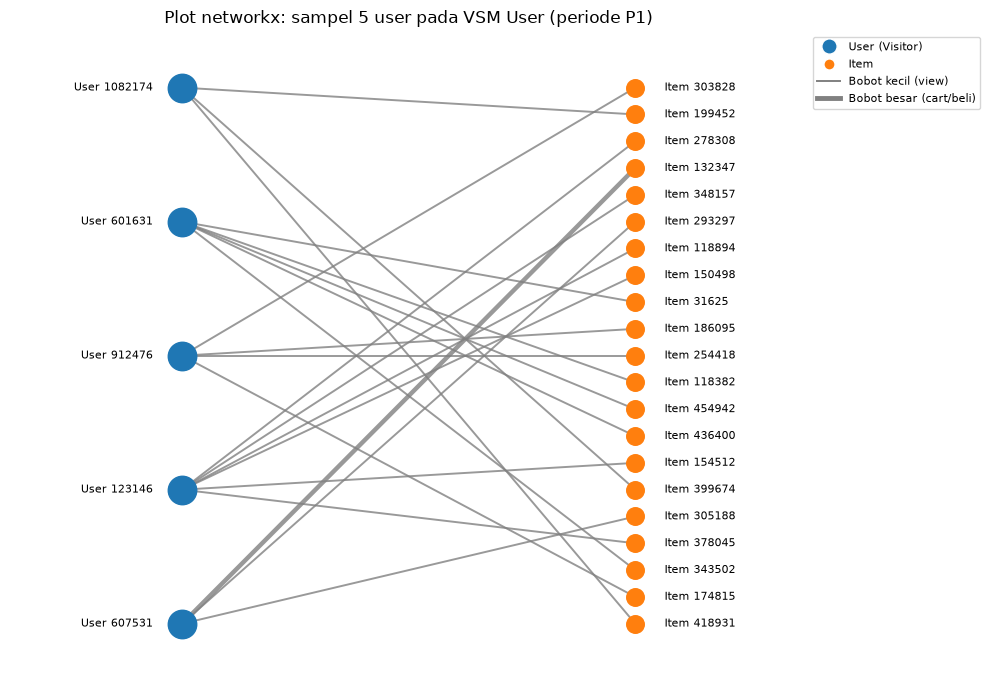

Simpul: 26 | Edge: 21
User terpilih (visitorId): [1082174, 607531, 912476, 123146, 601631]


In [8]:
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

jumlah_item = edges.groupby("u").size()
kandidat = jumlah_item[(jumlah_item >= 3) & (jumlah_item <= 6)].index
rng = np.random.default_rng(42)
pilih = rng.choice(kandidat.to_numpy(), size=5, replace=False)
sampel = edges[edges["u"].isin(pilih)]

users = [f"User {u}" for u in sorted(sampel["u"].unique())]
items = [f"Item {i}" for i in sorted(sampel["i"].unique())]
G = nx.Graph()
G.add_nodes_from(users, bipartite=0)
G.add_nodes_from(items, bipartite=1)
for u_, i_, w_ in zip(sampel["u"], sampel["i"], sampel["w"]):
    G.add_edge(f"User {u_}", f"Item {i_}", bobot=int(w_))

pos = nx.bipartite_layout(G, users, align="vertical")
tebal = [0.8 + 0.6 * G[a][b]["bobot"] for a, b in G.edges]

plt.figure(figsize=(10, 7))
nx.draw_networkx_edges(G, pos, width=tebal, edge_color="gray", alpha=0.8)
nx.draw_networkx_nodes(G, pos, nodelist=users, node_color="tab:blue", node_size=420)
nx.draw_networkx_nodes(G, pos, nodelist=items, node_color="tab:orange", node_size=160)
nx.draw_networkx_labels(G, {n: (x - 0.08, y) for n, (x, y) in pos.items() if n in users},
                        labels={n: n for n in users}, horizontalalignment="right", font_size=8)
nx.draw_networkx_labels(G, {n: (x + 0.08, y) for n, (x, y) in pos.items() if n in items},
                        labels={n: n for n in items}, horizontalalignment="left", font_size=8)

legenda = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor="tab:blue", markersize=11, label="User (Visitor)"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="tab:orange", markersize=8, label="Item"),
    Line2D([0], [0], color="gray", lw=1.4, label="Bobot kecil (view)"),
    Line2D([0], [0], color="gray", lw=3.5, label="Bobot besar (cart/beli)"),
]
plt.legend(handles=legenda, loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=8)
plt.title("Plot networkx: sampel 5 user pada VSM User (periode P1)")
plt.margins(x=0.3)
plt.axis("off")
plt.tight_layout()
plt.show()

print("Simpul:", G.number_of_nodes(), "| Edge:", G.number_of_edges())
print("User terpilih (visitorId):", [int(u) for u in pilih])

**Plot networkx.**

Plot menampilkan sampel 5 user yang dipilih acak (seed 42) dari user yang memiliki 3 sampai 6 item pada periode P1. Simpul biru adalah User (`Visitor`) dan simpul oranye adalah `Item`; ketebalan garis menunjukkan bobot interaksi (semakin tebal, semakin besar bobotnya, karena `ADDED_TO_CART` dan `BOUGHT` diberi bobot lebih besar daripada `VIEWED`).

Graf berbentuk bipartit: edge hanya menghubungkan User dengan Item, tidak ada edge antar-User maupun antar-Item. Sampel ini terdiri atas 26 simpul (5 user dan 21 item) dengan 21 edge. Setiap item hanya terhubung ke satu user, sehingga tiap user membentuk "bintang" kecil yang terpisah dan tidak ada item yang dibagi oleh dua user. Hal ini mencerminkan sifat VSM User yang sangat jarang (*sparse*): dari ribuan kemungkinan item, satu user hanya menyentuh sedikit item, dan dua user hanya mirip bila berbagi item yang sama.

**Visualisasi subgraph User-Item di Neo4j**

Subgraph berikut diambil langsung dari Neo4j dengan query Cypher di bawah ini (6 user yang pernah
melakukan pembelian, masing-masing maksimal 8 item).

```cypher
MATCH (v:Visitor)-[:BOUGHT]->(:Item)
WITH DISTINCT v ORDER BY v.visitorId LIMIT 6
CALL (v) {
    MATCH (v)-[r]->(i:Item)
    RETURN r, i
    ORDER BY CASE type(r) WHEN 'BOUGHT' THEN 0 WHEN 'ADDED_TO_CART' THEN 1 ELSE 2 END, i.itemId
    LIMIT 8
}
RETURN v, r, i
```

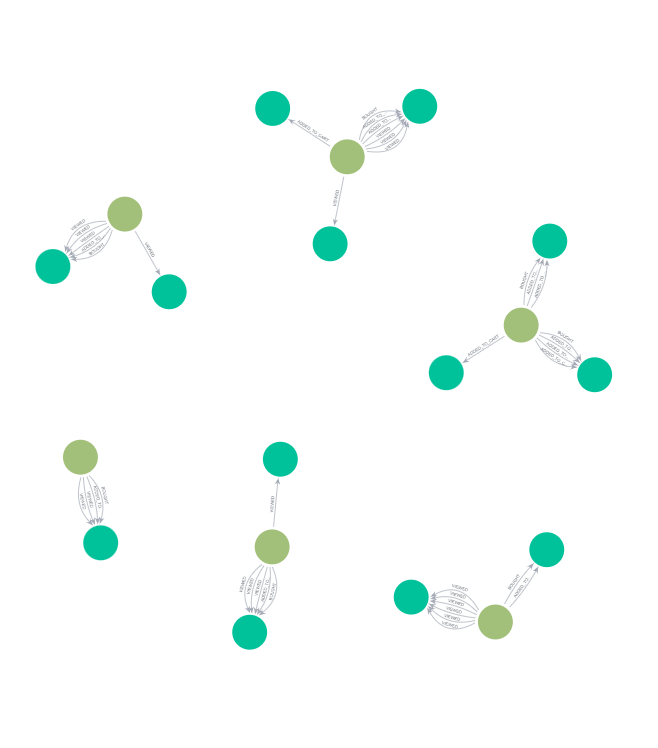

**Penjelasan.** Gambar menampilkan simpul `Visitor` (User) dan simpul `Item` yang dihubungkan relasi
`VIEWED`, `ADDED_TO_CART`, dan `BOUGHT`. Graf berbentuk bipartit berarah: relasi hanya mengalir dari User
ke Item, tidak ada relasi antar-User maupun antar-Item. Setiap user membentuk gugus kecil dengan item-itemnya,
sehingga terlihat bahwa satu user hanya menyentuh sedikit item. Hal ini mencerminkan VSM User yang sangat
jarang (*sparse*): dua user baru dianggap mirip bila mereka berbagi item yang sama.

### 2.1.5 VSM Item

In [9]:
MI = M.T.tocsr()                          
n_item, n_user = MI.shape
user_per_item = MI.getnnz(axis=1)        

print("Shape MI:", MI.shape)
ringkas = pd.Series({
    "Jumlah item (baris)": n_item,
    "Dimensi vektor item (= jumlah user)": n_user,
    "Shape matriks (item x user)": str(MI.shape),
    "Sel terisi (nnz)": MI.nnz,
    "Total sel": n_item * n_user,
    "Density": f"{MI.nnz / (n_item * n_user):.6%}",
    "Sparsity": f"{1 - MI.nnz / (n_item * n_user):.4%}",
    "Memori dense (GB)": round(n_item * n_user * 8 / 1e9, 2),
    "Memori sparse (MB)": round((MI.data.nbytes + MI.indices.nbytes + MI.indptr.nbytes) / 1e6, 2),
    "User per item: rata-rata": round(float(user_per_item.mean()), 2),
    "User per item: median": float(np.median(user_per_item)),
    "User per item: maksimum": int(user_per_item.max()),
    "Item dengan tepat 1 user (%)": round(float((user_per_item == 1).mean() * 100), 2),
    "Item dengan >= 2 user (%)": round(float((user_per_item >= 2).mean() * 100), 2),
}).to_frame("Nilai")
display(ringkas)

kelompok = pd.cut(user_per_item, bins=[0, 1, 2, 5, 10, np.inf], labels=["1", "2", "3-5", "6-10", ">10"])
tabel = pd.Series(kelompok).value_counts().sort_index().rename("jumlah item").to_frame()
tabel["persentase"] = (tabel["jumlah item"] / n_item * 100).round(2)
display(tabel)

contoh = int(np.argmax(user_per_item))
vektor = MI[contoh]
print("Item contoh (itemId):", i_ids[contoh])
print("Shape vektor:", vektor.shape, "| elemen non-nol:", vektor.nnz)
display(pd.DataFrame({"visitorId": u_ids[vektor.indices[:5]], "bobot": vektor.data[:5]}))

Shape MI: (53450, 83096)


,Nilai
Jumlah item (baris),53450
Dimensi vektor item (= jumlah user),83096
Shape matriks (item x user),"(53450, 83096)"
Sel terisi (nnz),121577
Total sel,4441481200
Density,0.002737%
Sparsity,99.9973%
Memori dense (GB),35.53
Memori sparse (MB),1.67
User per item: rata-rata,2.27


,jumlah item,persentase
1,32807,61.38
2,9147,17.11
3-5,7718,14.44
6-10,2533,4.74
>10,1245,2.33


Item contoh (itemId): 389814
Shape vektor: (1, 83096) | elemen non-nol: 137


,visitorId,bobot
0,4348,4
1,24827,1
2,30809,1
3,52772,1
4,71425,6


**Karakteristik VSM Item**

Pada VSM Item, setiap simpul `Item` direpresentasikan sebagai satu vektor baris pada matriks interaksi item × user, yaitu transpos dari matriks user × item pada VSM User. Setiap elemen berisi bobot interaksi (`VIEWED` = 1, `ADDED_TO_CART` = 3, `BOUGHT` = 5), dan bobot dijumlahkan apabila satu user berinteraksi lebih dari sekali dengan item yang sama.

**Dimensi dan shape.** Matriks berukuran **53.450 × 83.096**, yaitu 53.450 item (baris) dan 83.096 user (kolom). Setiap vektor item berdimensi **83.096**, sama dengan jumlah simpul `Visitor`. Hal ini berkebalikan dengan vektor User yang berdimensi 53.450. Total sel pada matriks adalah 53.450 × 83.096 = 4.441.481.200.

**Sparsity.** Hanya **121.577** sel yang terisi (nnz), sehingga *density* hanya **0,002737%** dan *sparsity* mencapai **99,9973%**. Nilai ini sama dengan matriks User karena `MI` hanyalah transpos dari `M`. Representasi dense akan membutuhkan memori sekitar **35,53 GB**, sedangkan format sparse (`csr_matrix`) hanya memakai sekitar **1,67 MB**, sehingga format sparse wajib digunakan.

**Sebaran aktivitas item.** Rata-rata satu item disentuh oleh **2,27 user** berbeda (median **1**), dengan nilai maksimum **137 user**. Sebanyak **61,38%** item hanya disentuh oleh satu user, sedangkan **38,62%** item (20.643 item) disentuh oleh dua user atau lebih.

| Jumlah user per item | Jumlah item | Persentase |
|---|---|---|
| 1 | 32.807 | 61,38% |
| 2 | 9.147 | 17,11% |
| 3 - 5 | 7.718 | 14,44% |
| 6 - 10 | 2.533 | 4,74% |
| > 10 | 1.245 | 2,33% |

Distribusi ini berpola *long tail*: mayoritas item hanya disentuh satu atau dua user, sedangkan 2,33% item populer disentuh oleh lebih dari 10 user. Namun, sebaran ini jauh lebih merata daripada sisi User, karena persentase item yang hanya disentuh satu user (61,38%) lebih kecil daripada persentase user yang hanya menyentuh satu item (81,5%).

**Contoh satu vektor item.** Item dengan `itemId` 389814 adalah item terpopuler, dengan vektor berbentuk (1, 83.096) yang memiliki **137 elemen non-nol**, yaitu sekitar 0,16% dari seluruh dimensinya. Lima elemen pertamanya berasal dari user 4348 (bobot 4), 24827 (bobot 1), 30809 (bobot 1), 52772 (bobot 1), dan 71425 (bobot 6). Bobot 1 berarti user tersebut hanya sekali melihat item, sedangkan bobot 4 dan 6 merupakan hasil penjumlahan beberapa interaksi pada item yang sama. Contoh ini menunjukkan bahwa seterkenal apa pun sebuah item, vektornya tetap jarang dibandingkan dimensi penuhnya.

**Implikasi.** Kemiripan antar-item hanya dapat dihitung bila dua item disentuh oleh user yang sama (irisan elemen non-nol). Pada sisi Item, 38,62% item disentuh minimal dua user, sedangkan pada sisi User hanya 18,5% user yang menyentuh minimal dua item. Namun, angka ini belum menunjukkan seberapa luas simpul yang memiliki tetangga pada graf proyeksi, karena sebuah item baru memiliki tetangga bila ada user yang menyentuh item itu dan item lain. Perbandingan jumlah pasangan terhubung, cakupan simpul yang memiliki tetangga, dan efisiensi memori antara proyeksi User-User dan Item-Item dibahas pada 2.1.6.

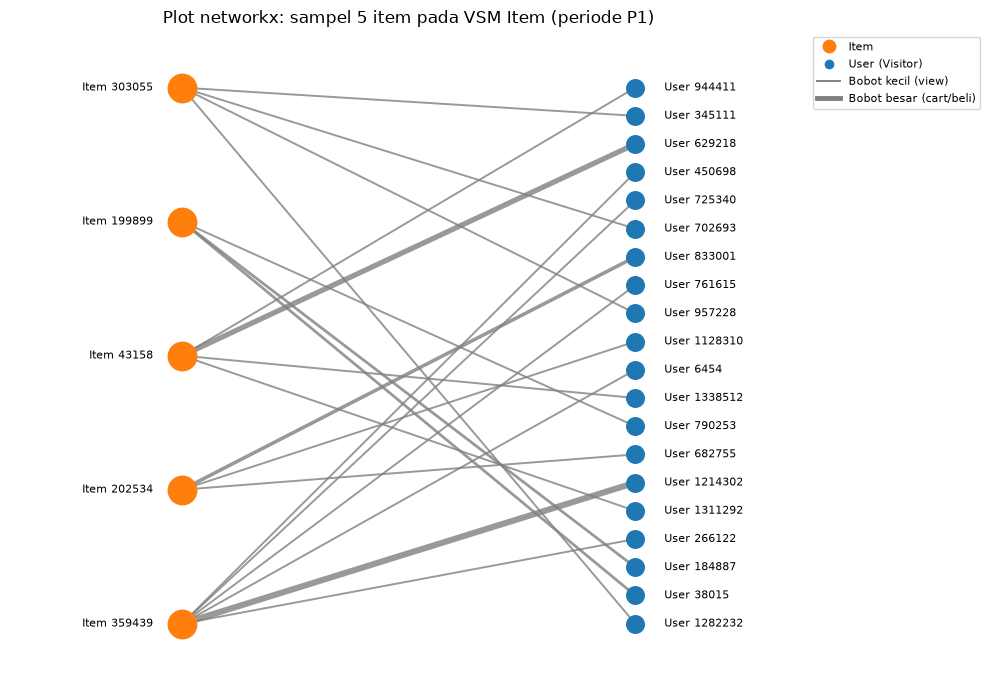

Simpul: 25 | Edge: 20
Item terpilih (itemId): [359439, 202534, 303055, 43158, 199899]
User yang menyentuh >1 item: 0


In [10]:
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

jumlah_user = edges.groupby("i").size()
kandidat_i = jumlah_user[(jumlah_user >= 3) & (jumlah_user <= 6)].index
rng = np.random.default_rng(42)
pilih_i = rng.choice(kandidat_i.to_numpy(), size=5, replace=False)
sampel_i = edges[edges["i"].isin(pilih_i)]

item_nodes = [f"Item {i}" for i in sorted(sampel_i["i"].unique())]
user_nodes = [f"User {u}" for u in sorted(sampel_i["u"].unique())]
GI = nx.Graph()
GI.add_nodes_from(item_nodes, bipartite=0)
GI.add_nodes_from(user_nodes, bipartite=1)
for u_, i_, w_ in zip(sampel_i["u"], sampel_i["i"], sampel_i["w"]):
    GI.add_edge(f"Item {i_}", f"User {u_}", bobot=int(w_))

pos_i = nx.bipartite_layout(GI, item_nodes, align="vertical")
tebal = [0.8 + 0.6 * GI[a][b]["bobot"] for a, b in GI.edges]

plt.figure(figsize=(10, 7))
nx.draw_networkx_edges(GI, pos_i, width=tebal, edge_color="gray", alpha=0.8)
nx.draw_networkx_nodes(GI, pos_i, nodelist=item_nodes, node_color="tab:orange", node_size=420)
nx.draw_networkx_nodes(GI, pos_i, nodelist=user_nodes, node_color="tab:blue", node_size=160)
nx.draw_networkx_labels(GI, {n: (x - 0.08, y) for n, (x, y) in pos_i.items() if n in item_nodes},
                        labels={n: n for n in item_nodes}, horizontalalignment="right", font_size=8)
nx.draw_networkx_labels(GI, {n: (x + 0.08, y) for n, (x, y) in pos_i.items() if n in user_nodes},
                        labels={n: n for n in user_nodes}, horizontalalignment="left", font_size=8)
plt.legend(handles=[
    Line2D([0], [0], marker="o", color="w", markerfacecolor="tab:orange", markersize=11, label="Item"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="tab:blue", markersize=8, label="User (Visitor)"),
    Line2D([0], [0], color="gray", lw=1.4, label="Bobot kecil (view)"),
    Line2D([0], [0], color="gray", lw=3.5, label="Bobot besar (cart/beli)"),
], loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=8)
plt.title("Plot networkx: sampel 5 item pada VSM Item (periode P1)")
plt.margins(x=0.3); plt.axis("off"); plt.tight_layout(); plt.show()

print("Simpul:", GI.number_of_nodes(), "| Edge:", GI.number_of_edges())
print("Item terpilih (itemId):", [int(i) for i in pilih_i])
print("User yang menyentuh >1 item:", sum(1 for n in user_nodes if GI.degree(n) > 1))

**Plot networkx.**

Plot menampilkan sampel 5 item yang dipilih acak (seed 42) dari item yang disentuh oleh 3 sampai 6 user pada periode P1. Simpul oranye di kolom kiri adalah `Item`, simpul biru di kolom kanan adalah `Visitor` (User), dan ketebalan garis menunjukkan bobot interaksi. Garis tebal berarti bobot besar, yaitu `ADDED_TO_CART`, `BOUGHT`, atau beberapa kali `VIEWED` pada pasangan yang sama, sedangkan garis tipis umumnya satu kali `VIEWED`.

Graf berbentuk bipartit: edge hanya menghubungkan Item dengan User, tanpa edge antar-Item maupun antar-User. Sampel ini terdiri atas 25 simpul (5 item dan 20 user) dengan 20 edge. Jumlah user per item bervariasi, dari 3 user (item 199899 dan 202534) sampai 6 user (item 359439), sesuai rentang pemilihan sampel. Sebagian besar garis tipis, dan hanya beberapa pasangan yang bobotnya besar, misalnya item 359439 dengan user 1214302 dan item 202534 dengan user 833001.

Setiap user pada sampel ini hanya terhubung ke satu item, sehingga kelima item membentuk lima "bintang" kecil yang terpisah dan tidak ada user yang menjembatani dua item. Akibatnya, kelima item ini tidak memiliki irisan dimensi, dan similarity di antara mereka bernilai nol. Hal ini mencerminkan sifat VSM Item yang sangat jarang (*sparse*): dari 83.096 dimensi user, satu item hanya memiliki beberapa elemen non-nol. Perlu dicatat bahwa plot hanya sampel kecil dari 53.450 item, sehingga bentuknya memberi gambaran struktur, bukan angka yang mewakili seluruh graf.

**Visualisasi subgraph Item-User di Neo4j**

Subgraph berikut diambil langsung dari Neo4j dengan query Cypher di bawah ini (6 item yang pernah dibeli, masing-masing maksimal 8 user).

```cypher
MATCH (:Visitor)-[:BOUGHT]->(i:Item)
WITH DISTINCT i ORDER BY i.itemId LIMIT 6
CALL (i) {
    MATCH (v:Visitor)-[r]->(i)
    RETURN v, r
    ORDER BY CASE type(r) WHEN 'BOUGHT' THEN 0 WHEN 'ADDED_TO_CART' THEN 1 ELSE 2 END, v.visitorId
    LIMIT 8
}
RETURN i, r, v
```

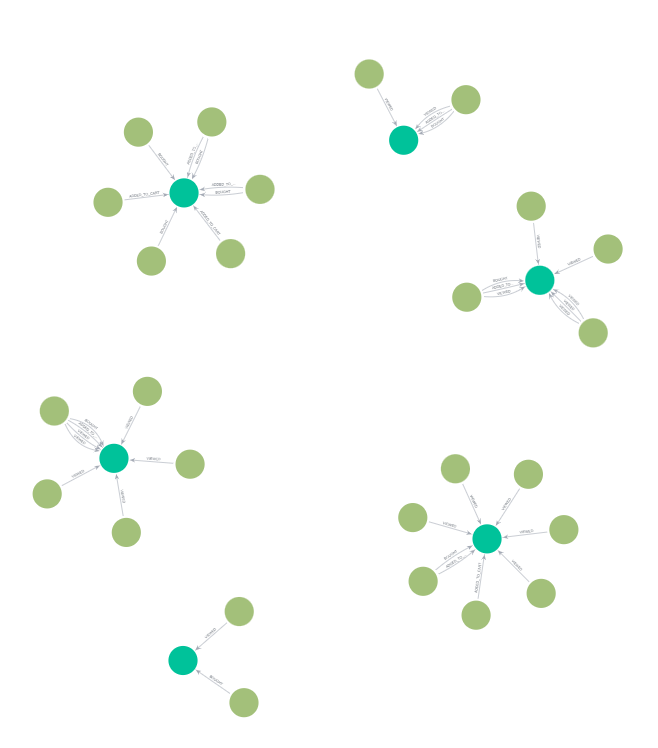

**Penjelasan.** Gambar menampilkan enam simpul `Item` (hijau toska) yang masing-masing dikelilingi oleh simpul `Visitor` (hijau olive) yang pernah berinteraksi dengannya. Panah berarah dari User ke Item dengan label jenis relasinya (`VIEWED`, `ADDED_TO_CART`, dan `BOUGHT`), sehingga graf berbentuk bipartit berarah: tidak ada relasi antar-Item maupun antar-User. Jumlah user per item bervariasi, dari dua user (dua item di sisi atas dan bawah) sampai tujuh user (item di kanan bawah), dan masing-masing item membentuk gugus berbentuk bintang dengan item sebagai pusatnya.

Pada beberapa pasangan terlihat lebih dari satu panah paralel antara user yang sama dan item yang sama, misalnya `ADDED_TO_CART` dan `BOUGHT` sekaligus. Hal ini terjadi karena query mengembalikan setiap relasi secara terpisah, sedangkan pada matriks VSM Item bobot-bobot tersebut dijumlahkan menjadi satu sel per pasangan user-item. Keenam gugus saling terpisah, dan tidak ada satu pun user yang menghubungkan dua item pada sampel ini. Hal ini mencerminkan VSM Item yang sangat jarang (*sparse*): dua item baru dianggap mirip bila disentuh oleh user yang sama, sedangkan pada sampel ini irisan semacam itu tidak ada.

Perlu dicatat bahwa item pada gambar dipilih dari item yang pernah dibeli (`BOUGHT`), sehingga cenderung lebih banyak diakses daripada item rata-rata (61,38% item hanya disentuh satu user). Gambar ini memberi gambaran struktur, bukan sampel yang mewakili seluruh graf.

### 2.1.6	Perbandingan Proyeksi

In [11]:
import time
from scipy.sparse.csgraph import connected_components

A  = M.copy();  A.data[:] = 1          
AI = A.T.tocsr()                      

def proyeksi(B):
    t0 = time.time()
    P = (B @ B.T).tocsr()              
    P.setdiag(0); P.eliminate_zeros()  
    waktu = time.time() - t0
    n = P.shape[0]
    deg = np.diff(P.indptr)
    _, label = connected_components(P, directed=False)
    komp = np.bincount(label)
    return {
        "Jumlah simpul": n,
        "Matriks kemiripan penuh": f"{n:,} x {n:,}".replace(",", "."),
        "Memori dense (GB)": round(n * n * 8 / 1e9, 2),
        "Pasangan terhubung": P.nnz // 2,
        "Density (%)": round(P.nnz / (n * n) * 100, 5),
        "Memori sparse (MB)": round((P.data.nbytes + P.indices.nbytes + P.indptr.nbytes) / 1e6, 2),
        "Waktu bangun (detik)": round(waktu, 2),
        "Simpul tanpa tetangga": int((deg == 0).sum()),
        "Simpul tanpa tetangga (%)": round((deg == 0).mean() * 100, 2),
        "Derajat rata-rata": round(float(deg.mean()), 2),
        "Derajat median": float(np.median(deg)),
        "Derajat maksimum": int(deg.max()),
        "Jumlah komponen": len(komp),
        "Komponen terbesar (simpul)": int(komp.max()),
        "Komponen terbesar (%)": round(komp.max() / n * 100, 2),
    }

hasil6 = pd.DataFrame({"User-User": proyeksi(A), "Item-Item": proyeksi(AI)})
display(hasil6)

,User-User,Item-Item
Jumlah simpul,83096,53450
Matriks kemiripan penuh,83.096 x 83.096,53.450 x 53.450
Memori dense (GB),55.24,22.86
Pasangan terhubung,410094,934700
Density (%),0.01188,0.06543
Memori sparse (MB),10.17,22.65
Waktu bangun (detik),0.02,0.04
Simpul tanpa tetangga,21942,26331
Simpul tanpa tetangga (%),26.41,49.26
Derajat rata-rata,9.87,34.97


In [12]:
uu, ii = hasil6["User-User"], hasil6["Item-Item"]
terhubung = {"User-User": int(uu["Jumlah simpul"] - uu["Simpul tanpa tetangga"]),
             "Item-Item": int(ii["Jumlah simpul"] - ii["Simpul tanpa tetangga"])}

tambahan = pd.DataFrame({
    "User-User": {
        "Simpul dengan >= 1 tetangga": terhubung["User-User"],
        "Simpul dengan >= 1 tetangga (%)": round(100 - float(uu["Simpul tanpa tetangga (%)"]), 2),
        "Derajat rata-rata (simpul terhubung)": round(2 * uu["Pasangan terhubung"] / terhubung["User-User"], 2),
    },
    "Item-Item": {
        "Simpul dengan >= 1 tetangga": terhubung["Item-Item"],
        "Simpul dengan >= 1 tetangga (%)": round(100 - float(ii["Simpul tanpa tetangga (%)"]), 2),
        "Derajat rata-rata (simpul terhubung)": round(2 * ii["Pasangan terhubung"] / terhubung["Item-Item"], 2),
    },
}, dtype=object)
display(tambahan)

rasio = pd.Series({
    "Pasangan terhubung Item-Item / User-User (x)": round(ii["Pasangan terhubung"] / uu["Pasangan terhubung"], 2),
    "Memori sparse Item-Item / User-User (x)": round(ii["Memori sparse (MB)"] / uu["Memori sparse (MB)"], 2),
    "Simpul User-User / Item-Item (x)": round(uu["Jumlah simpul"] / ii["Jumlah simpul"], 2),
    "Memori dense User-User / Item-Item (x)": round(uu["Memori dense (GB)"] / ii["Memori dense (GB)"], 2),
}).to_frame("Rasio")
display(rasio)

,User-User,Item-Item
Simpul dengan >= 1 tetangga,61154.0,27119.0
Simpul dengan >= 1 tetangga (%),73.59,50.74
Derajat rata-rata (simpul terhubung),13.41,68.93


,Rasio
Pasangan terhubung Item-Item / User-User (x),2.28
Memori sparse Item-Item / User-User (x),2.23
Simpul User-User / Item-Item (x),1.55
Memori dense User-User / Item-Item (x),2.42


**Perbandingan Proyeksi**

Proyeksi **Item-Item** dipilih sebagai proyeksi yang lebih baik secara keseluruhan (lebih efisien pada ukuran simpul, dengan sinyal kemiripan per simpul yang lebih kuat), dengan beberapa catatan.

1. **Lebih efisien pada ukuran simpul.** Item-Item memiliki 53.450 simpul dibandingkan 83.096 pada User-User (sekitar 36% lebih sedikit). Matriks kemiripan penuhnya juga jauh lebih kecil (22,86 GB vs 55,24 GB dalam bentuk dense), dan waktu bangunnya lebih singkat (0,21 vs 0,59 detik). Dengan simpul yang lebih sedikit, ruang pencarian tetangga lebih kecil.
2. **Sinyal per simpul lebih kuat.** Density Item-Item 0,06543% atau sekitar 5,5 kali lebih tinggi daripada User-User (0,01188%), dan derajat rata-ratanya 34,97 dibandingkan 9,87. Artinya satu item rata-rata terhubung ke lebih banyak item lain daripada satu user ke user lain.
3. **Lebih stabil antar-periode.** Katalog item relatif tetap antara P1 dan P2, sedangkan pengunjung bersifat sementara: hanya 3.780 user yang muncul di kedua periode, dari 83.096 user P1. Kemiripan item yang dipelajari di P1 karena itu lebih mungkin masih berlaku di P2.

**Caveat / trade-off.**
- Item-Item memiliki lebih banyak pasangan terhubung (934.700 vs 410.094) dan memori sparse lebih besar (22,65 MB vs 10,17 MB), sehingga dari sisi jumlah edge User-User lebih ringan.
- Proporsi simpul terisolasi Item-Item lebih besar (49,26% vs 26,41%), derajat mediannya hanya 1 (User-User: 3), dan komponen terbesarnya lebih kecil (37,64% vs 47,03%). Banyak item hanya dilihat satu user yang tidak melihat item lain, dan kepadatan terkonsentrasi pada item populer.
- Kedua proyeksi memiliki jumlah komponen yang sama (29.062) karena berasal dari graf bipartit yang sama.
- User-User tetap berguna untuk rekomendasi yang dipersonalisasi, sehingga digunakan untuk KNN pada bagian 2.2. Untuk perhitungan similarity pada soal no. 7 dipilih Item-Item.

### 2.1.7	Similarity

In [13]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

item_acuan_id = 357779
idx_acuan = np.where(i_ids == item_acuan_id)[0][0]

M_item = M.T.tocsr()
vektor_acuan = M_item[idx_acuan]

sim_scores = cosine_similarity(vektor_acuan, M_item).flatten()

top_indices = np.argsort(sim_scores)[::-1]
top_indices = [idx for idx in top_indices if idx != idx_acuan][:5]

df_sim = pd.DataFrame({
    'item_acuan': item_acuan_id,
    'item_mirip': i_ids[top_indices],
    'similarity_score': sim_scores[top_indices]
})

print("Hasil Perhitungan Similarity di Python:")
print(df_sim)

Hasil Perhitungan Similarity di Python:
   item_acuan  item_mirip  similarity_score
0      357779      242493          0.777482
1      357779       66597          0.777482
2      357779      403343          0.777482
3      357779      257410          0.774587
4      357779      304558          0.625624


In [14]:
# WRITE-BACK SIMILARITY KE GRAF NEO4J
cypher_write_back = """
UNWIND $batch AS row
MATCH (i1:Item {itemId: row.item_acuan})
MATCH (i2:Item {itemId: row.item_mirip})
MERGE (i1)-[r:SIMILAR_TO]->(i2)
SET r.score = row.similarity_score
"""

batch_data = df_sim.to_dict(orient="records")

with driver.session(database="neo4j") as session:
    session.run(cypher_write_back, batch=batch_data)


# QUERY CYPHER TOP 5 RECORDS DARI GRAF NEO4J
cypher_show_results = """
MATCH (acuan:Item {itemId: $item_id})-[r:SIMILAR_TO]->(target:Item)
RETURN acuan.itemId AS `Item Acuan`, 
       target.itemId AS `Item Termirip`, 
       r.score AS `Nilai Similarity`
ORDER BY r.score DESC
LIMIT 5
"""

records, _, _ = driver.execute_query(
    cypher_show_results, 
    item_id=item_acuan_id, 
    database_="neo4j"
)

df_hasil_neo4j = pd.DataFrame([r.data() for r in records])

print("\nHasil Query 5 Record Similarity Tertinggi dari Graf Neo4j:")
display(df_hasil_neo4j)


Hasil Query 5 Record Similarity Tertinggi dari Graf Neo4j:


,Item Acuan,Item Termirip,Nilai Similarity
0,357779,66597,0.777482
1,357779,242493,0.777482
2,357779,403343,0.777482
3,357779,257410,0.774587
4,357779,304558,0.625624


### 2.1.8	Graf Sebelum dan Sesudah Similarity

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd

item_acuan_id = 357779
database_name = "neo4j"

def get_graph_data(item_id, include_similarity=False):
    if not include_similarity:
        # 1. Query Cypher KONDISI SEBELUM (Tanpa SIMILAR_TO)
        cypher_query = """
        MATCH (acuan:Item {itemId: $id})<-[r1]-(v:Visitor)
        MATCH (v)-[r2]->(other:Item)
        RETURN v.visitorId AS visitor, 
               other.itemId AS item, 
               null AS similarity_score
        LIMIT 100
        """
    else:
        # 2. Query Cypher KONDISI SESUDAH (Dengan SIMILAR_TO)
        cypher_query = """
        MATCH (acuan:Item {itemId: $id})-[s:SIMILAR_TO]->(target:Item)
        OPTIONAL MATCH (acuan)<-[r1]-(v:Visitor)-[r2]->(target)
        RETURN v.visitorId AS visitor, 
               target.itemId AS item, 
               s.score AS similarity_score
        """
    
    records, _, _ = driver.execute_query(
        cypher_query, 
        id=item_id, 
        database_=database_name
    )
    return pd.DataFrame([r.data() for r in records])


def draw_graph_condition(df_edges, reference_id, title=""):
    G = nx.Graph()
    
    reference_node = f"I_{reference_id}"
    G.add_node(reference_node)
    
    similarity_edges = []
    
    for row in df_edges.itertuples():
        if pd.notna(row.visitor):
            v_node = f"U_{int(row.visitor)}"
            G.add_edge(v_node, reference_node, type="INTERACTION")
            if pd.notna(row.item):
                i_node = f"I_{int(row.item)}"
                G.add_edge(v_node, i_node, type="INTERACTION")
                
        if pd.notna(row.similarity_score) and pd.notna(row.item):
            target_node = f"I_{int(row.item)}"
            G.add_edge(reference_node, target_node, type="SIMILAR_TO")
            similarity_edges.append((reference_node, target_node, float(row.similarity_score)))

    visitor_nodes = [n for n in G.nodes if n.startswith("U_")]
    item_nodes = [n for n in G.nodes if n.startswith("I_") and n != reference_node]
    
    pos = nx.spring_layout(G, seed=42)
    plt.figure(figsize=(10, 7))
    
    interaction_edges = [(u, v) for u, v, d in G.edges(data=True) if d.get('type') == 'INTERACTION']
    nx.draw_networkx_edges(G, pos, edgelist=interaction_edges, alpha=0.3, edge_color="gray")

    if similarity_edges:
        sim_edge_list = [(u, v) for u, v, _ in similarity_edges]
        nx.draw_networkx_edges(G, pos, edgelist=sim_edge_list, edge_color="red", style="dashed", width=2)
        
        edge_labels = {(u, v): f"{score:.3f}" for u, v, score in similarity_edges}
        nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=8, font_color="red")

    nx.draw_networkx_nodes(G, pos, nodelist=visitor_nodes, node_color="#1f77b4", node_size=100, label="Visitor")
    nx.draw_networkx_nodes(G, pos, nodelist=item_nodes, node_color="#ff7f0e", node_size=150, label="Other Item")
    nx.draw_networkx_nodes(G, pos, nodelist=[reference_node], node_color="#d62728", node_size=350, label="Reference Item")
    
    labels = {n: n for n in G.nodes if n == reference_node or n in item_nodes}
    nx.draw_networkx_labels(G, pos, labels=labels, font_size=8, font_weight="bold")

    plt.title(title, fontsize=12, fontweight='bold')
    plt.legend(scatterpoints=1, loc='upper left')
    plt.axis("off")
    plt.show()


Kondisi Sebelum (Before)
Query Cypher Sebelum:

MATCH (acuan:Item {itemId: 357779})<-[r1]-(v:Visitor)
MATCH (v)-[r2]->(other:Item)
RETURN acuan, r1, v, r2, other



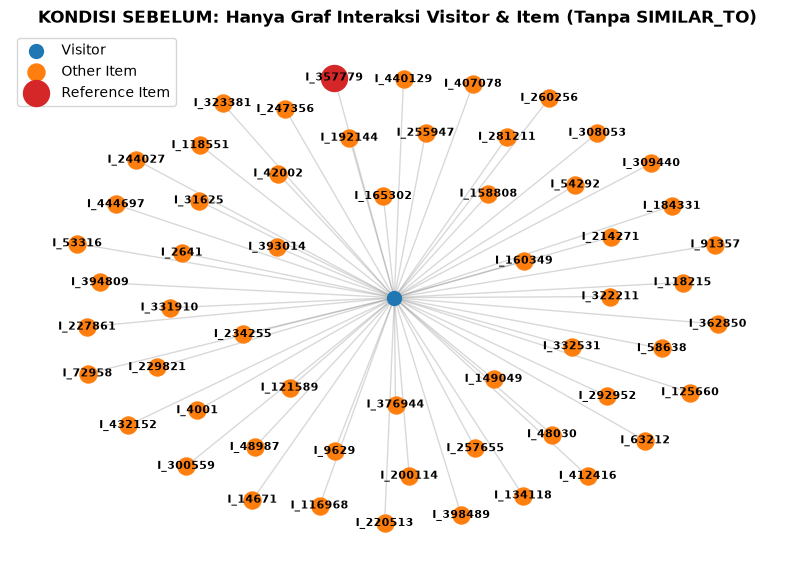

In [63]:
print("Kondisi Sebelum (Before)")
print("Query Cypher Sebelum:")
print("""
MATCH (acuan:Item {itemId: 357779})<-[r1]-(v:Visitor)
MATCH (v)-[r2]->(other:Item)
RETURN acuan, r1, v, r2, other
""")

df_before = get_graph_data(item_acuan_id, include_similarity=False)
draw_graph_condition(df_before, item_acuan_id, title="KONDISI SEBELUM: Hanya Graf Interaksi Visitor & Item (Tanpa SIMILAR_TO)")


 Kondisi Sesudah (After)
Query Cypher Sesudah:

MATCH (acuan:Item {itemId: 357779})-[s:SIMILAR_TO]->(target:Item)
OPTIONAL MATCH (acuan)<-[r1]-(v:Visitor)-[r2]->(target)
RETURN acuan, s, target, v, r1, r2



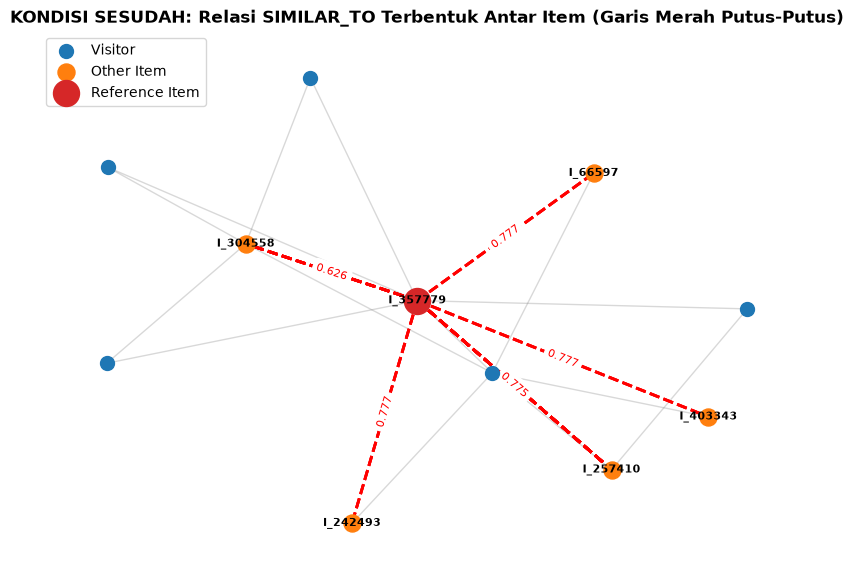

In [64]:
print("\n Kondisi Sesudah (After)")
print("Query Cypher Sesudah:")
print("""
MATCH (acuan:Item {itemId: 357779})-[s:SIMILAR_TO]->(target:Item)
OPTIONAL MATCH (acuan)<-[r1]-(v:Visitor)-[r2]->(target)
RETURN acuan, s, target, v, r1, r2
""")

df_after = get_graph_data(item_acuan_id, include_similarity=True)
draw_graph_condition(df_after, item_acuan_id, title="KONDISI SESUDAH: Relasi SIMILAR_TO Terbentuk Antar Item (Garis Merah Putus-Putus)")

## 2.2 Analytics
Pada bagian ini digunakan KNN berbasis user (user-based collaborative filtering): rekomendasi untuk seorang user diambil dari item yang disentuh oleh 5 user paling mirip (berdasarkan cosine similarity pada VSM User dari data P1). Data P2 dipakai sebagai kunci jawaban evaluasi.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity
 
SEED = 42       
K = 5            
N_REKOM = 5      
N_IKLAN = 3      

uid2row = {int(u): r for r, u in enumerate(u_ids)}
 
def rekomendasi_knn(user_id, k=K, n=N_REKOM):
    r = uid2row[int(user_id)]
    sim = cosine_similarity(M[r], M).ravel()
    sim[r] = -1                                             
 
    urut = np.lexsort((u_ids, -sim))                       
    nbr = [j for j in urut[:k] if sim[j] > 0]               
    df_nbr = pd.DataFrame({
        "peringkat": range(1, len(nbr) + 1),
        "visitorId": u_ids[nbr],
        "similarity": sim[nbr],
        "jumlah_item": M[nbr].getnnz(axis=1),
    })
 
    skor = np.zeros(M.shape[1])
    for j in nbr:
        skor += sim[j] * M[j].toarray().ravel()
    skor[M[r].indices] = 0                                  
 
    kand = np.flatnonzero(skor > 0)
    top = kand[np.lexsort((i_ids[kand], -skor[kand]))][:n]   
    df_rek = pd.DataFrame({
        "rank": range(1, len(top) + 1),
        "itemId": i_ids[top],
        "skor": skor[top],
    })
    return df_nbr, df_rek

### 2.2.1(a) Skrip KNN untuk Rekomendasi
Cara kerja fungsi rekomendasi_knn:
1. Hitung cosine similarity user target terhadap semua user lain pada matriks VSM User (M).
2. Pilih k = 5 tetangga dengan similarity tertinggi (similarity harus lebih dari 0).
3. Skor item = jumlah (similarity tetangga × bobot interaksi tetangga pada item tersebut).
4. Buang item yang sudah pernah disentuh user target di P1, lalu urutkan dari skor tertinggi. Jika skor sama, item dengan ID lebih kecil didahulukan agar hasilnya deterministik.

In [ ]:
p2_items = p2.groupby("visitorid")["itemid"].apply(lambda s: set(s.astype(int)))
 
kandidat = []
for u in sorted(int(x) for x in u_ids if int(x) in p2_items.index):
    p1_items = set(i_ids[M[uid2row[u]].indices].astype(int))
    if not (p2_items[u] - p1_items):
        continue                                           
    _, rek = rekomendasi_knn(u)
    if len(rek) == N_REKOM:
        kandidat.append(u)
 
print("Kandidat memenuhi syarat:", len(kandidat))
 
rng = np.random.default_rng(SEED)
user_terpilih = int(rng.choice(np.array(kandidat)))
print("User terpilih (visitorId):", user_terpilih)
 
df_nbr, df_rek = rekomendasi_knn(user_terpilih)
 
riwayat = M[uid2row[user_terpilih]]
print(f"Riwayat user {user_terpilih} di P1: {riwayat.nnz} item")
print("Item (maks. 10):", i_ids[riwayat.indices[:10]].tolist(), "| bobot:", riwayat.data[:10].tolist())
print(f"\nTetangga KNN (k = {K}):")
display(df_nbr)

Kandidat memenuhi syarat: 461
User terpilih (visitorId): 140772
Riwayat user 140772 di P1: 1 item
Item (maks. 10): [133415] | bobot: [1]

Tetangga KNN (k = 5):


,peringkat,visitorId,similarity,jumlah_item
0,1,181771,1.000000,1
1,2,315280,1.000000,1
2,3,1098537,1.000000,1
3,4,708592,0.813733,11
4,5,1296988,0.377964,4


**Pemilihan user acak (reproducible)**

Prosesnya: daftar user yang muncul di P1 dan P2 diurutkan menurut visitorId, lalu satu user dipilih dengan np.random.default_rng(42). Daftar tersebut hanya berisi user yang:
- menghasilkan 5 item rekomendasi, dan
- memiliki minimal satu item di P2 yang belum pernah disentuh di P1 (agar rekomendasi dari P1 mungkin menjadi hit).

Syarat ini diperlukan karena 81,5% user hanya menyentuh satu item, sehingga banyak user tidak menghasilkan rekomendasi. Konsekuensinya, hasil evaluasi hanya berlaku untuk user yang memenuhi syarat. Terdapat «ISI: jumlah kandidat» kandidat, dan user terpilih adalah **visitorId 140772**.

### 2.2.1(b) Tiga item yang diiklankan (k = 5)

In [22]:
iklan = df_rek.head(N_IKLAN)
print(f"{N_IKLAN} item yang diiklankan untuk user {user_terpilih} (k = {K}):")
display(iklan)
 
print("Daftar rekomendasi lengkap (top-5, dipakai untuk 2.2.2):")
display(df_rek)

kunci_p2 = p2_items[user_terpilih]
print("\nItem yang diakses user di P2 (kunci jawaban):", sorted(kunci_p2))
print("Item P2 yang belum ada di P1:", sorted(kunci_p2 - set(i_ids[riwayat.indices].astype(int))))

3 item yang diiklankan untuk user 140772 (k = 5):


,rank,itemId,skor
0,1,356315,2.383396
1,2,453816,2.005431
2,3,101718,1.627467


Daftar rekomendasi lengkap (top-5, dipakai untuk 2.2.2):


,rank,itemId,skor
0,1,356315,2.383396
1,2,453816,2.005431
2,3,101718,1.627467
3,4,175668,1.627467
4,5,243170,1.627467



Item yang diakses user di P2 (kunci jawaban): [387377]
Item P2 yang belum ada di P1: [387377]


Tiga item dengan skor tertinggi dari KNN dipilih sebagai iklan, yaitu 
- item **356315** (skor 2,383396) 
- item **453816** (2,005431)
- item **101718** (1,627467). 

Daftar top-5 juga ditampilkan karena dipakai untuk menghitung Hit@5 dan NDCG@5; dua item berikutnya adalah 175668 dan 243170 (keduanya bernilai 1,627467). Peringkat 3, 4, dan 5 memiliki skor sama, sehingga urutannya ditentukan oleh aturan itemId terkecil.

### 2.2.2 - Evaluasi: Hit@5 dan NDCG@5
Kunci jawaban adalah item yang diakses user di **P2** dan belum pernah disentuh di P1 (item P1 tidak pernah direkomendasikan, sehingga tidak dihitung sebagai target). Rumus yang dipakai:
- **Hit@5** = 1 jika minimal satu dari 5 item rekomendasi ada di kunci jawaban, selain itu 0.
- **DCG@5** = jumlah rel_i / log2(i + 1) untuk posisi i = 1..5, dengan rel_i = 1 jika item pada posisi i ada di kunci jawaban.
- **NDCG@5** = DCG@5 dibagi DCG ideal (semua item relevan berada di posisi teratas).

In [23]:
kunci_baru = kunci_p2 - set(i_ids[riwayat.indices].astype(int))
 
def hit_ndcg_at_k(rekomendasi, kunci, k=5):
    rekomendasi = list(rekomendasi)[:k]
    rel = np.array([1 if int(i) in kunci else 0 for i in rekomendasi])
    diskon = 1 / np.log2(np.arange(2, len(rel) + 2))        # 1/log2(i+1), i = 1..k
    dcg = float((rel * diskon).sum())
    n_ideal = min(len(kunci), k)
    idcg = float((1 / np.log2(np.arange(2, n_ideal + 2))).sum())
    hit = int(rel.sum() > 0)
    ndcg = dcg / idcg if idcg > 0 else 0.0
    return hit, ndcg, rel, dcg, idcg
 
hit5, ndcg5, rel, dcg, idcg = hit_ndcg_at_k(df_rek["itemId"], kunci_baru, k=5)
 
rincian = df_rek.copy()
rincian["relevan (rel)"] = rel
rincian["diskon 1/log2(rank+1)"] = 1 / np.log2(rincian["rank"] + 1)
display(rincian)
 
print("User                    :", user_terpilih)
print("Kunci jawaban (P2 baru) :", sorted(kunci_baru))
print("Rekomendasi top-5       :", df_rek["itemId"].tolist())
print(f"\n(a) Hit@5  = {hit5}")
print(f"(b) DCG@5  = {dcg:.4f} | IDCG@5 = {idcg:.4f}")
print(f"    NDCG@5 = {ndcg5:.4f}")

,rank,itemId,skor,relevan (rel),diskon 1/log2(rank+1)
0,1,356315,2.383396,0,1.000000
1,2,453816,2.005431,0,0.630930
2,3,101718,1.627467,0,0.500000
3,4,175668,1.627467,0,0.430677
4,5,243170,1.627467,0,0.386853


User                    : 140772
Kunci jawaban (P2 baru) : [387377]
Rekomendasi top-5       : [356315, 453816, 101718, 175668, 243170]

(a) Hit@5  = 0
(b) DCG@5  = 0.0000 | IDCG@5 = 1.0000
    NDCG@5 = 0.0000


**Mengapa hasilnya 0.** Kunci jawaban user 140772 hanya berisi satu item, yaitu **387377**, sedangkan lima item rekomendasinya adalah 356315, 453816, 101718, 175668, dan 243170. Tidak ada satu pun yang sama dengan kunci jawaban, sehingga seluruh nilai `rel` pada tabel adalah 0. Konsekuensinya:
- **Hit@5 = 0**, karena tidak ada item relevan di lima besar.
- **DCG@5 = 0**, karena DCG adalah jumlah `rel × diskon` dan semua `rel` bernilai 0.
- **IDCG@5 = 1**, karena kunci jawaban hanya satu item. Kondisi idealnya adalah item itu berada di peringkat 1, yaitu 1 / log2(2) = 1.
- **NDCG@5 = 0 / 1 = 0**.

Nilai nol ini adalah hasil perhitungan yang benar dan bukan kesalahan program. Kecilnya peluang hit wajar pada data ini: user hanya punya satu item target di antara 53.450 item, dan rekomendasi hanya bersumber dari 5 tetangga, sehingga item target harus kebetulan disentuh oleh tetangga tersebut dan mendapat skor cukup tinggi agar masuk lima besar.

Peringkat 3, 4, dan 5 memiliki skor yang sama (1,627467), sehingga urutan di antara ketiganya ditentukan oleh aturan `itemId` terkecil, bukan oleh perbedaan kualitas. Hal ini tidak memengaruhi hasil di atas karena kunci jawaban tidak ada di antara kelima item tersebut. Selain itu, evaluasi pada satu user hanya menghasilkan nilai 0 atau 1 (atau pecahan sederhana), sehingga hasil ini tidak menggambarkan kualitas model secara umum dan hanya menunjukkan bahwa pada user ini item yang diakses di P2 tidak termasuk dalam lima rekomendasi teratas.